# 06 — фаза 6: DINO ViT у DETR, 3 seed (EXPLORATORY)

Ноутбук лише читає `reports/tables/phase6_*.csv` і `reports/figures/shift_*.png`. Гіпотезу сформульовано після test фази 5.
Деталі: `reports/phase6_stage2_summary.md`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from malaria_ssl.detr.compare import plot_paired_diffs
from malaria_ssl.utils.config import resolve_path

T = resolve_path('reports/tables')
F = resolve_path('reports/figures')


def ci(v, lo, hi):
    return f'{v:.3f} [{lo:.3f}, {hi:.3f}]'


def wide(df, index, columns, v='value', lo='ci_low', hi='ci_high'):
    """Long table of value + CI -> formatted pivot."""
    d = df.assign(s=[ci(a, b, c) for a, b, c in zip(df[v], df[lo], df[hi])])
    return d.pivot(index=index, columns=columns, values='s')


## Test infected AP50 за seed

In [2]:
r = pd.read_csv(T / 'phase6_stage2_runs.csv')
r['model'] = r['run'].str.replace(r'_seed4[34]$', '', regex=True)
r['seed'] = r['run'].str.extract(r'seed(4[34])$')[0].fillna('42')
t = r.pivot(index='model', columns='seed', values='test_AP50_infected')
t.assign(mean=t.mean(axis=1), std=t.std(axis=1)).round(3)

seed,42,43,44,mean,std
model,,,,,
a_coco_detr_binary,0.551,0.583,0.517,0.550,0.033
b_vit_dino_full,0.614,0.644,0.601,0.620,0.022
b_vit_imagenet,0.528,0.657,0.517,0.567,0.078


## Парні різниці середніх трьох seed

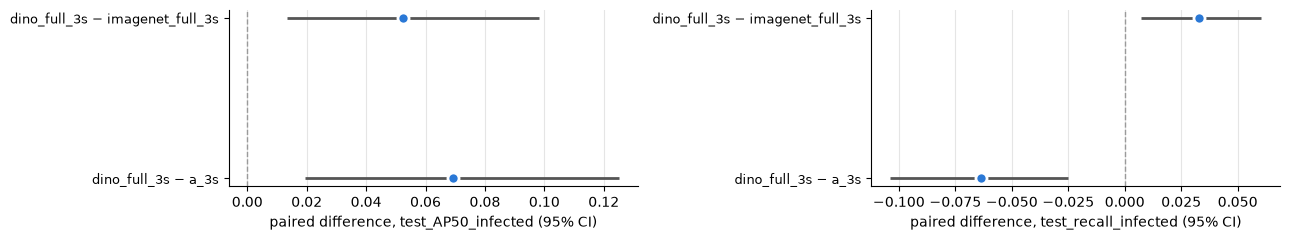

In [3]:
d = pd.read_csv(T / 'phase6_stage2_diff.csv')
d = d[d['a'] == 'dino_full_3s']
fig, axes = plt.subplots(1, 2, figsize=(13, 2.5))
plot_paired_diffs(d, 'test_AP50_infected', axes[0])
plot_paired_diffs(d, 'test_recall_infected', axes[1])
plt.tight_layout()

## Бокси чи класифікація

Class-agnostic AP50 проти infected AP50 на test.

In [4]:
b = pd.read_csv(T / 'phase6_stage2_box_vs_cls.csv')
b[b['split'] == 'test'].pivot(index='run', columns='metric', values='value').round(3)

metric,agnostic_AP50,agnostic_recall_all,agnostic_recall_infected,infected_AP50
run,,,,
a_coco_detr_binary,0.972,0.984,0.984,0.551
a_coco_detr_binary_seed43,0.971,0.986,0.984,0.583
a_coco_detr_binary_seed44,0.970,0.984,0.984,0.517
b_vit_dino_full,0.966,0.986,0.980,0.614
b_vit_dino_full_seed43,0.966,0.986,0.990,0.644
b_vit_dino_full_seed44,0.967,0.988,0.987,0.601
b_vit_imagenet,0.954,0.975,0.984,0.528
b_vit_imagenet_seed43,0.956,0.976,0.990,0.657
b_vit_imagenet_seed44,0.950,0.970,0.984,0.517


## Двоетапна схема DINO на боксах A

In [5]:
s = pd.read_csv(T / 'phase6_two_stage_dino_3s.csv')
s = s[(s['split'] == 'test') & s['run'].isin(['a_3s', 'dino_full_3s'])]
s.assign(AP50_ci=[ci(*x) for x in zip(s['AP50'], s['AP50_lo'], s['AP50_hi'])])[
    ['run', 'encoder', 'training', 'AP50_ci', 'precision', 'recall', 'f1']].round(3)

,run,encoder,training,AP50_ci,precision,recall,f1
25,a_3s,end_to_end,-,"0.550 [0.485, 0.620]",0.853,0.416,0.559
27,a_3s,ref_dino,clean,"0.680 [0.622, 0.743]",0.741,0.538,0.622
29,a_3s,ref_dino,stain,"0.670 [0.612, 0.731]",0.733,0.560,0.635
31,dino_full_3s,end_to_end,-,"0.620 [0.574, 0.676]",0.878,0.352,0.500


## Діагностика зсуву, DINO-DETR, seed 43

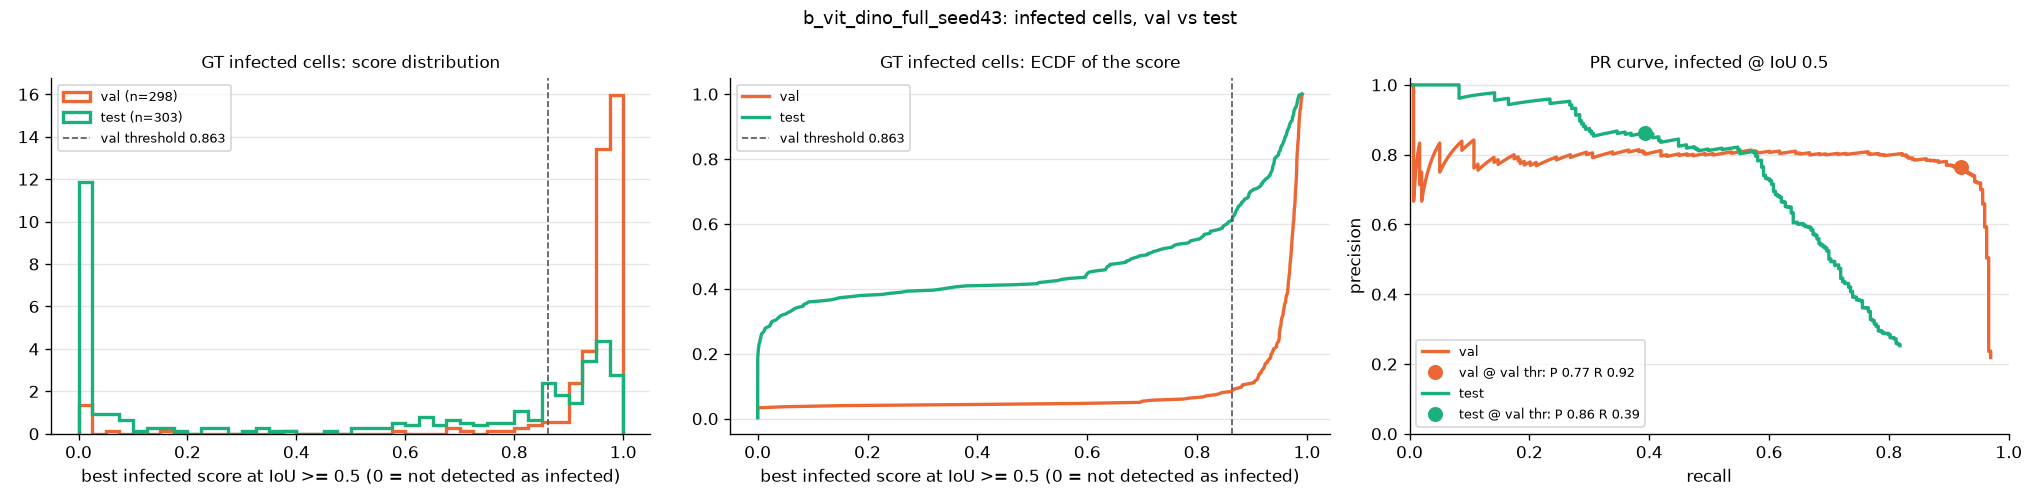

In [6]:
display(Image(filename=str(F / 'shift_b_vit_dino_full_seed43.png')))